# STEP 1

Why should I hire you to use machine learning in my problem if I have other people who are experts in AI/ML?'

I am an expert with many years of experience in the field. I have worked with the biggest clients in the country and was always able to provide a solution that made valuable changes to the business through my knowledge on ML.

# STEP 2 

What do you think at this stage you could offer the client? What other requirements would you have besides the information offered by the client? What kind of value can you deliver potentially to the client?

By looking at the database and process, we can offer the client a way to classify orders, meaning organize orders with similar characteristics into groups called clusters. This would allow us to find patterns that will be beneficial for optimizing order preparation and delivery by developing methods applicable for each type of order. Information like the date and time of each order could be useful details and will allow better separation.



# STEP 3 (EDA)

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Read csv 
df = pd.read_csv('WholesaleCustomersData.csv')

df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## Mean, STD, Min and Max 

In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


- There is 3 regions in the dataset.
- There is 2 channels in the dataset.
- Clients spend more, on average, on 'Fresh' and 'Grocery' and less on 'Delicassen'.

## 'Channel' Column Details

/var/folders/gh/qryqd19177z9xrl48m08rfg80000gn/T/ipykernel_9656/3306488899.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Channel', palette='pastel')


Channel
1    298
2    142
Name: count, dtype: int64

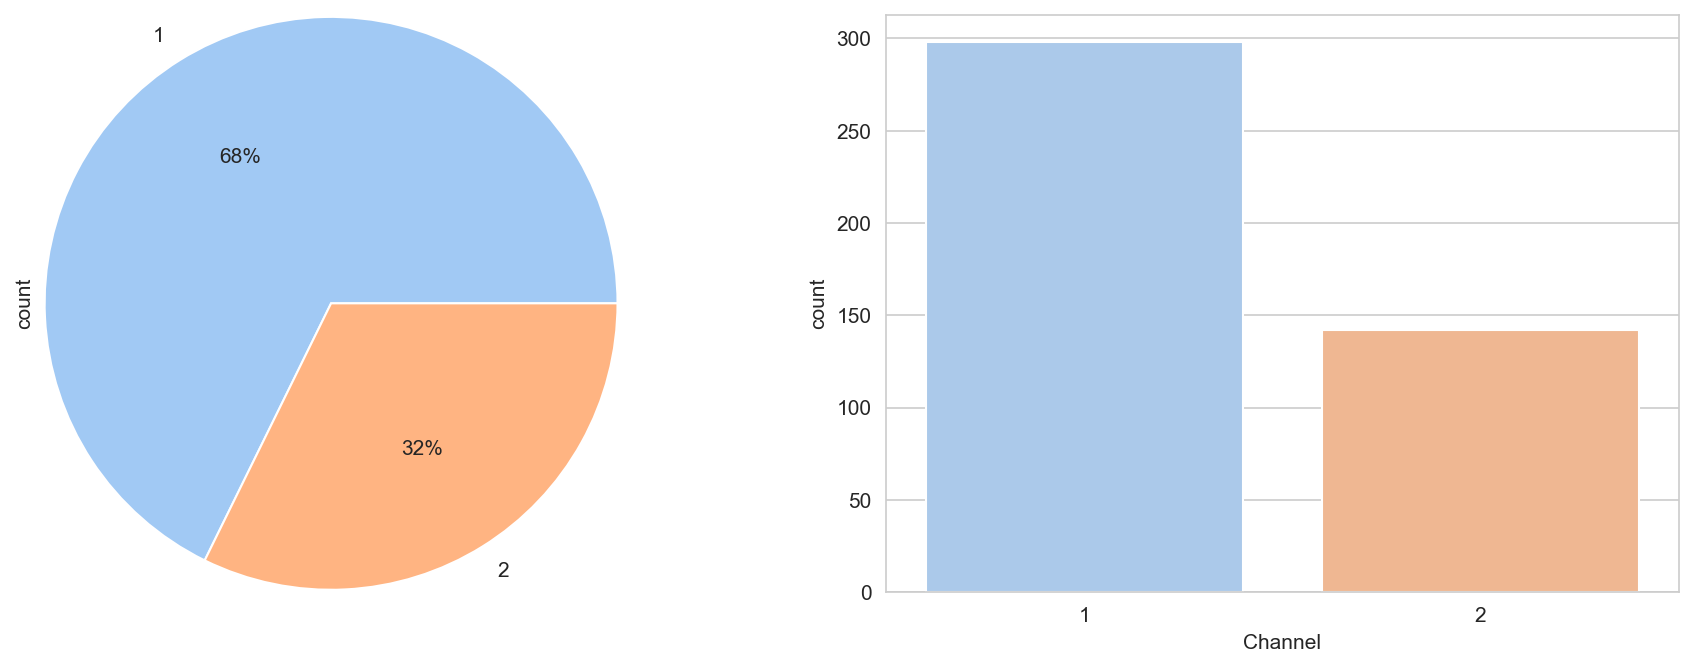

In [3]:
sns.set_style('whitegrid')
plt.figure(figsize=(15, 5), dpi=150)
plt.subplot(121)
df['Channel'].value_counts().plot(kind='pie', autopct='%2.f%%', radius=1.24, colors=sns.color_palette('pastel'))
plt.subplot(122)
sns.countplot(data=df, x='Channel', palette='pastel')
df['Channel'].value_counts()

- Channel 1 counts for 2/3 of the datapoints and Channel 2 for 1/3.

## 'Region' Column Details

/var/folders/gh/qryqd19177z9xrl48m08rfg80000gn/T/ipykernel_9656/2851177099.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Region', palette='pastel')


Region
3    316
1     77
2     47
Name: count, dtype: int64

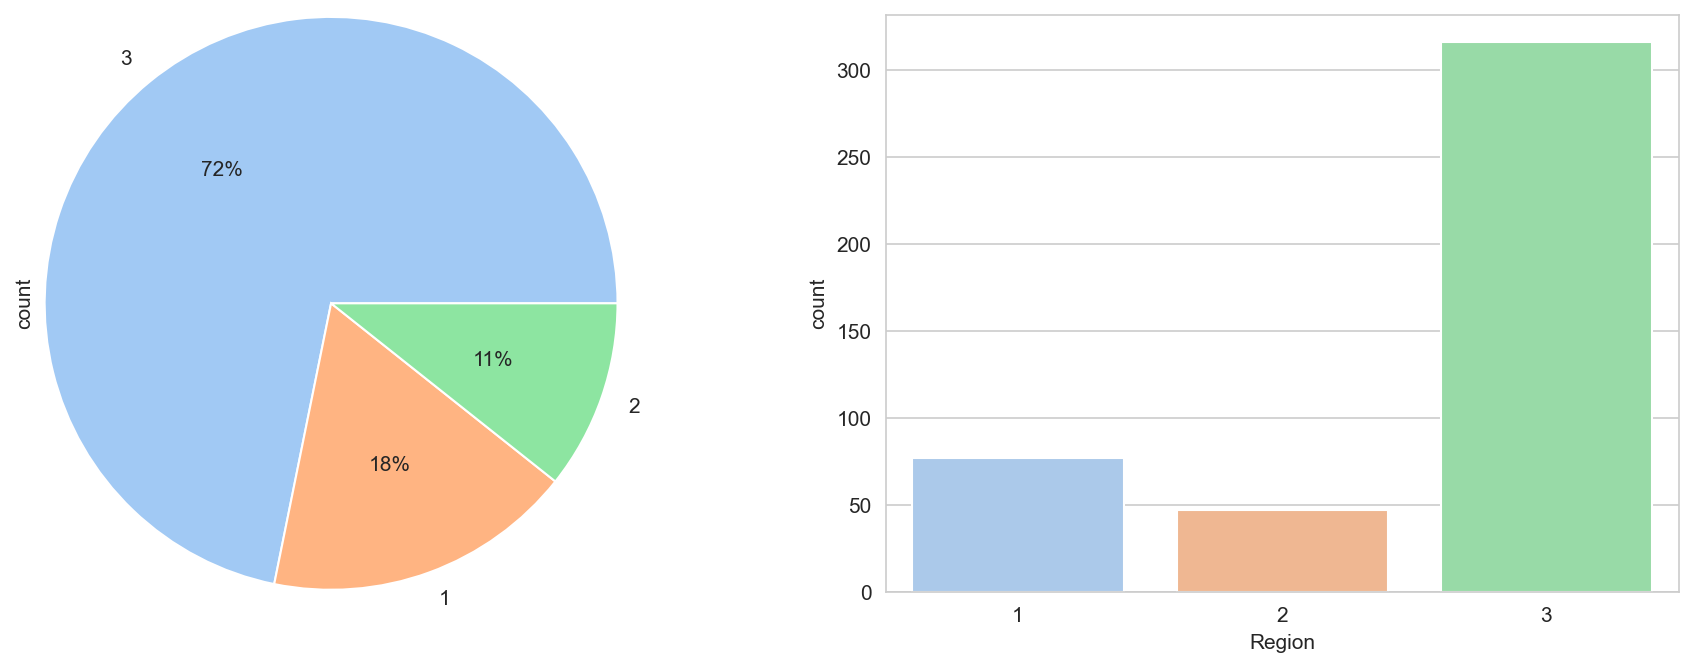

In [4]:
sns.set_style('whitegrid')
plt.figure(figsize=(15, 5), dpi=150)
plt.subplot(121)
df['Region'].value_counts().plot(kind='pie', autopct='%2.f%%', radius=1.24, colors=sns.color_palette('pastel'))
plt.subplot(122)
sns.countplot(data=df, x='Region', palette='pastel')
df['Region'].value_counts()

- Most of the datapoints (72%) are from region 3.

## Variables Histograms

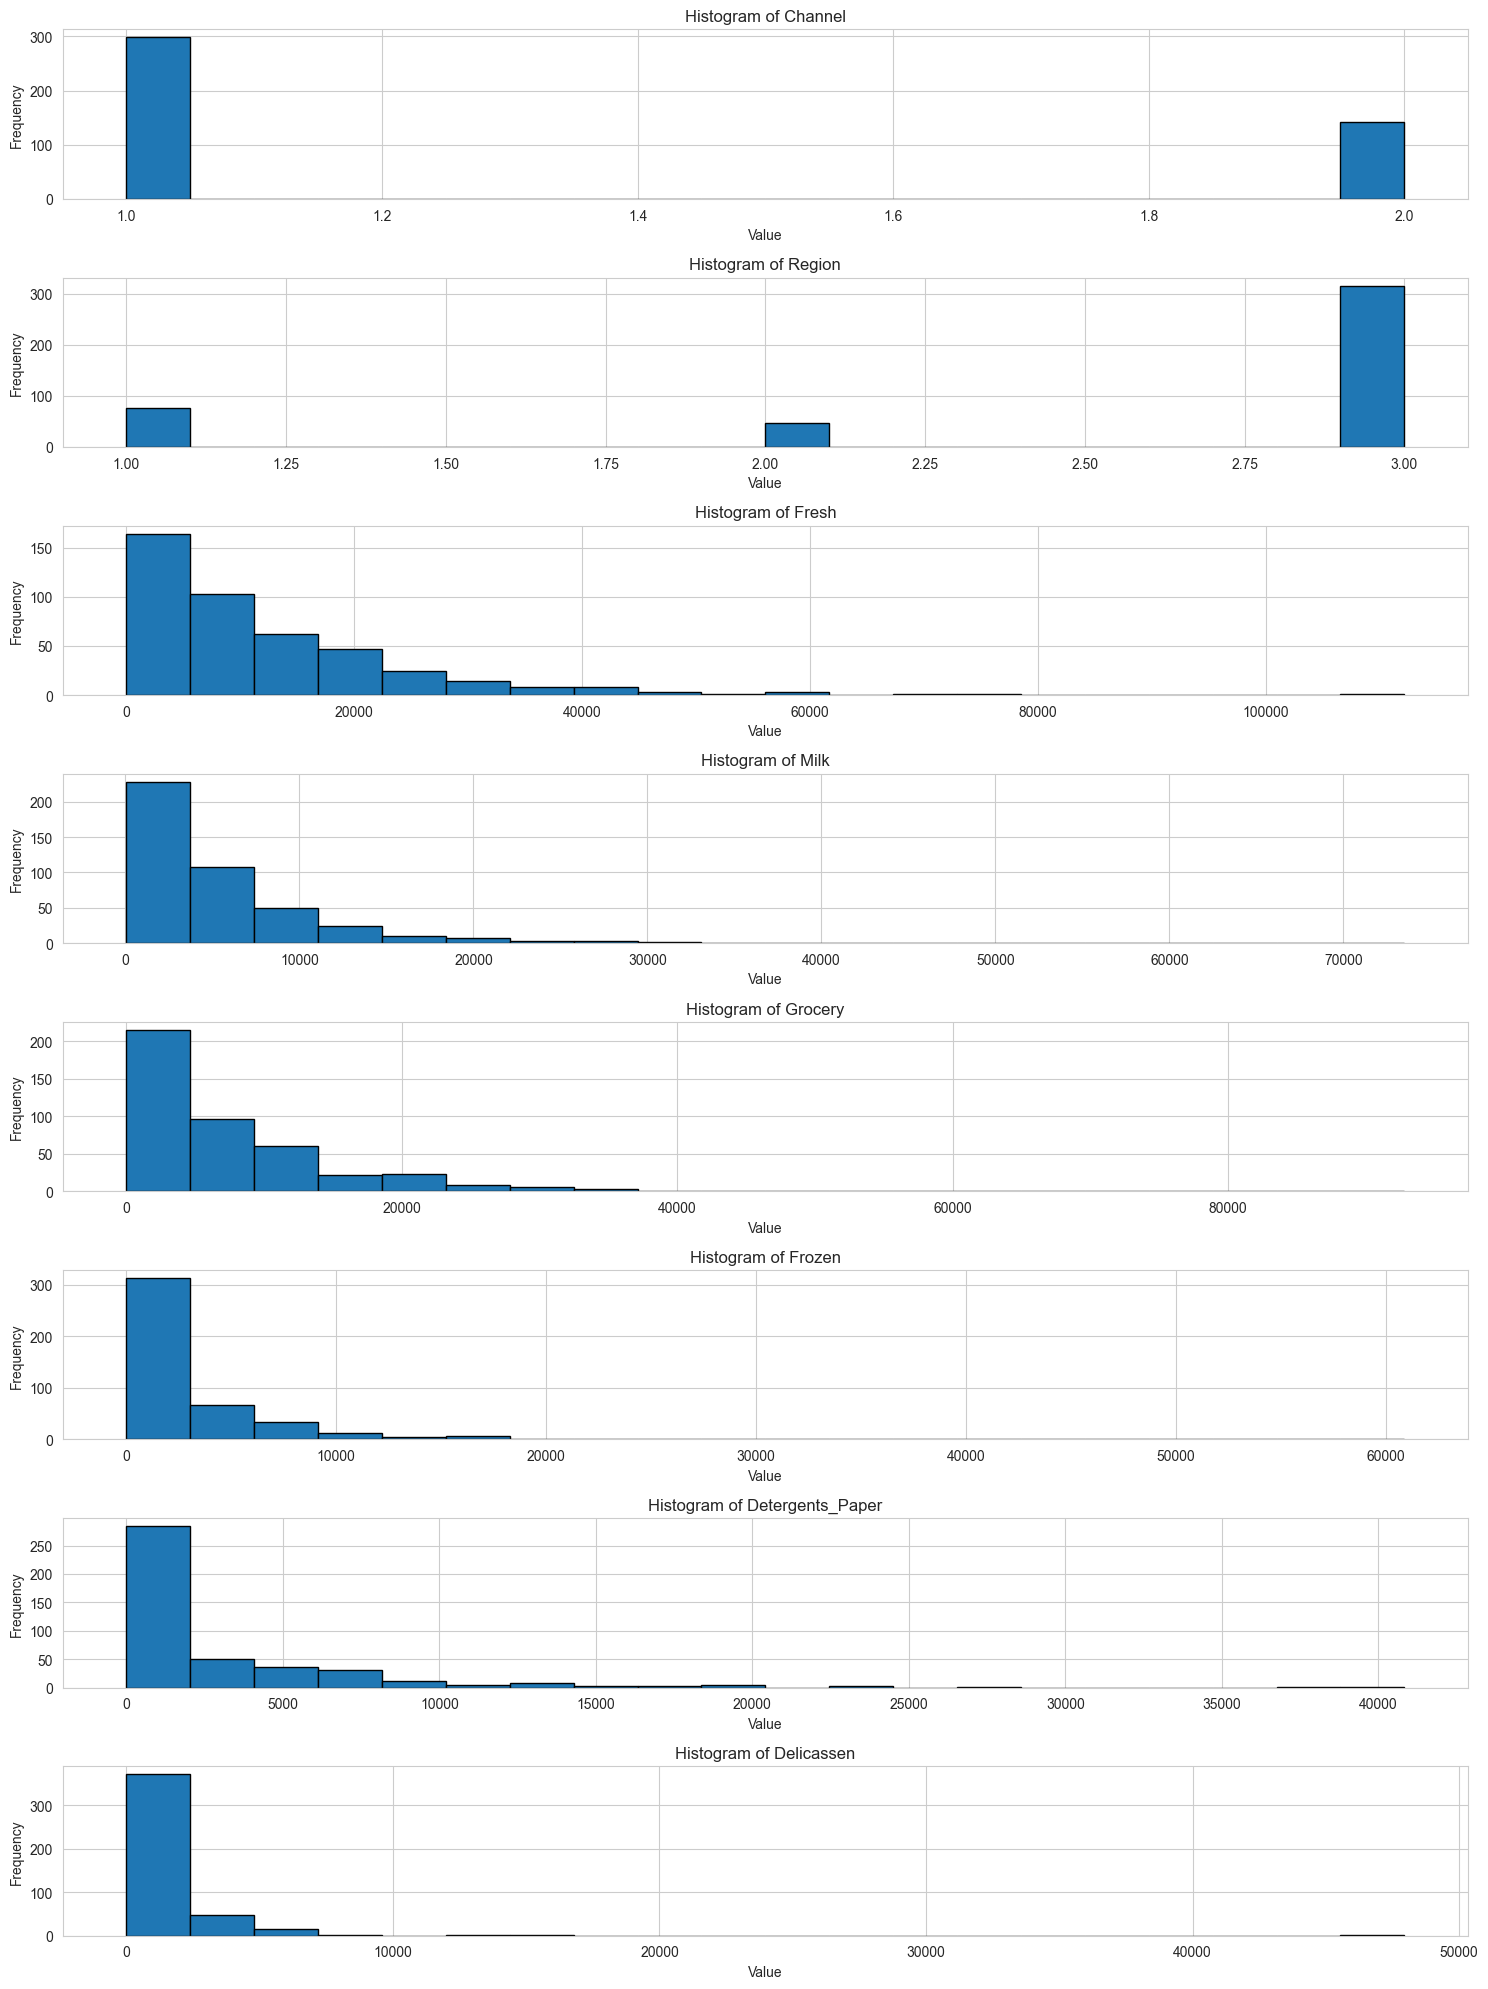

In [5]:
plt.figure(figsize=(15, 20))  

# Plot histograms for each feature
for i, feature in enumerate(df.columns, 1):
    plt.subplot(len(df.columns), 1, i)
    plt.hist(df[feature], bins=20, edgecolor='black')  # Increase bins if needed
    plt.title(f'Histogram of {feature}')
    plt.xlabel('Value')
    plt.ylabel('Frequency')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()

- 'Fresh' datapoints are noticeably more spread out on the 'Value' axis and less concentrated before the '10 000' value mark relative to the other variables. This means clients are more willing to spend more on fresh products.

- Datapoints for 'Frozen', 'Detergentss_paper' and 'Delicassen' variables are very concentrated under the '10 000' value mark, where 'Delicassen' datapoint concentration is by far closer to the origin. This indicates that spending for those product categories is relatively less.

## Correlation Matrix

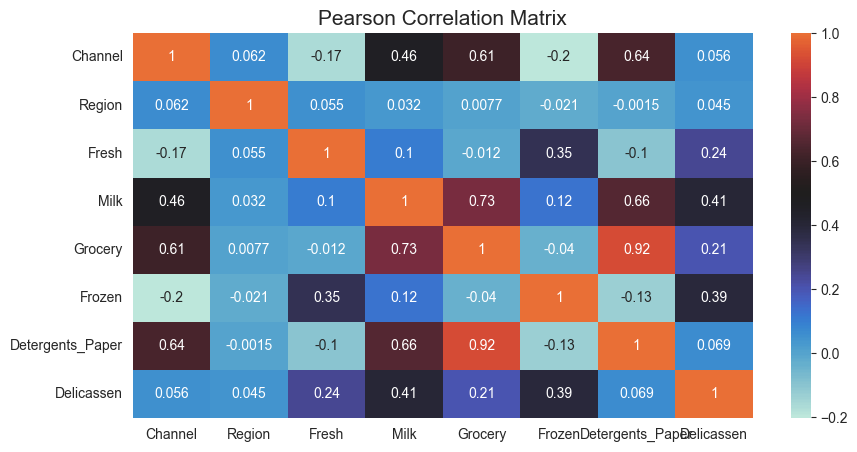

In [6]:
corr=df.corr()
plt.figure(figsize=(10,5))
plt.title('Pearson Correlation Matrix',fontsize=15)
sns.heatmap(corr, center=0.5,annot=True)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.show()

- 'Grocery' and 'Detergents_Paper' variables are closely correlated. Meaning, the more a client spends on grocery products, the more he is willing to spend on detergents and paper products, and vice versa.

# Step 4 (K-Means clustering)

In [7]:
df = df.drop( axis=0, columns='Channel') 
df = df.drop( axis=0, columns='Region')

from sklearn.preprocessing import StandardScaler

# Standardize the data
scaler = StandardScaler() 
scaled_data = scaler.fit_transform(df)

# Adding scaled data to dataframe
scaled_df = pd.DataFrame(scaled_data,columns=df.columns) 
scaled_df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


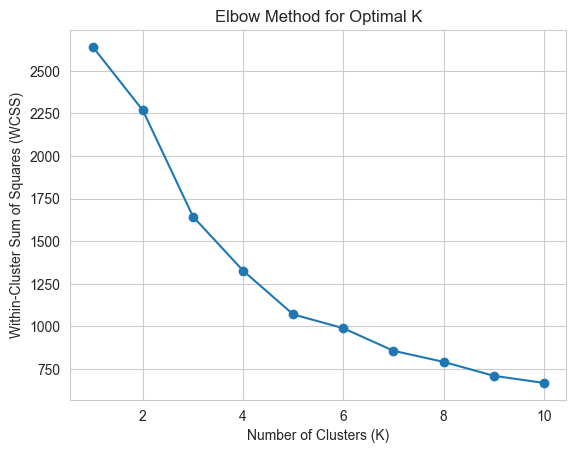

In [8]:
# In this cell, we are using the Elbow method to determine the ideal value of K.

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Elbow Method to find optimal number of clusters


wcss = []  # Within-Cluster Sum of Squares


# Trying K values from 1 to 10
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_df)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.show()

- Optimal k seems to be between 5 and 8.
  
Let's apply K-Means to the dataset with 5, 6, 7 and 8 clusters and see what the evaluation metrics say about each number of clusters. 

In [9]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Apply K-means with 5 clusters
print('     5 Clusters Model')

kmeans = KMeans(n_clusters=5, random_state=42)
scaled_df['cluster'] = kmeans.fit_predict(scaled_df)

# Silhouette Score
silhouette_avg = silhouette_score(scaled_data, scaled_df['cluster'])
print(f"Silhouette Score: {silhouette_avg:.2f}")

# Final Inertia
print(f"Final Inertia: {kmeans.inertia_:.2f}")

# Calinski-Harabasz Index
ch_score = calinski_harabasz_score(scaled_data, scaled_df['cluster'])
print(f"Calinski-Harabasz Score: {ch_score:.2f}")

# Davies-Bouldin Index
db_score = davies_bouldin_score(scaled_data, scaled_df['cluster'])
print(f"Davies-Bouldin Score: {db_score:.2f}\n")

# Apply K-means with 6 clusters
print('     6 Clusters Model')

kmeans = KMeans(n_clusters=6, random_state=42)
scaled_df['cluster'] = kmeans.fit_predict(scaled_df)

# Silhouette Score
silhouette_avg = silhouette_score(scaled_data, scaled_df['cluster'])
print(f"Silhouette Score: {silhouette_avg:.2f}")

# Final Inertia
print(f"Final Inertia: {kmeans.inertia_:.2f}")

# Calinski-Harabasz Index
ch_score = calinski_harabasz_score(scaled_data, scaled_df['cluster'])
print(f"Calinski-Harabasz Score: {ch_score:.2f}")

# Davies-Bouldin Index
db_score = davies_bouldin_score(scaled_data, scaled_df['cluster'])
print(f"Davies-Bouldin Score: {db_score:.2f}\n")

# Apply K-means with 7 clusters
print('     7 Clusters Model')

kmeans = KMeans(n_clusters=7, random_state=42)
scaled_df['cluster'] = kmeans.fit_predict(scaled_df)

# Silhouette Score
silhouette_avg = silhouette_score(scaled_data, scaled_df['cluster'])
print(f"Silhouette Score: {silhouette_avg:.2f}")

# Final Inertia
print(f"Final Inertia: {kmeans.inertia_:.2f}")

# Calinski-Harabasz Index
ch_score = calinski_harabasz_score(scaled_data, scaled_df['cluster'])
print(f"Calinski-Harabasz Score: {ch_score:.2f}")

# Davies-Bouldin Index
db_score = davies_bouldin_score(scaled_data, scaled_df['cluster'])
print(f"Davies-Bouldin Score: {db_score:.2f}\n")

# Apply K-means with 8 clusters
print('     8 Clusters Model')

kmeans = KMeans(n_clusters=8, random_state=42)
scaled_df['cluster'] = kmeans.fit_predict(scaled_df)

# Silhouette Score
silhouette_avg = silhouette_score(scaled_data, scaled_df['cluster'])
print(f"Silhouette Score: {silhouette_avg:.2f}")

# Final Inertia
print(f"Final Inertia: {kmeans.inertia_:.2f}")

# Calinski-Harabasz Index
ch_score = calinski_harabasz_score(scaled_data, scaled_df['cluster'])
print(f"Calinski-Harabasz Score: {ch_score:.2f}")

# Davies-Bouldin Index
db_score = davies_bouldin_score(scaled_data, scaled_df['cluster'])
print(f"Davies-Bouldin Score: {db_score:.2f}")

     5 Clusters Model
Silhouette Score: 0.37
Final Inertia: 1070.26
Calinski-Harabasz Score: 159.50
Davies-Bouldin Score: 1.03

     6 Clusters Model
Silhouette Score: 0.37
Final Inertia: 1013.11
Calinski-Harabasz Score: 140.91
Davies-Bouldin Score: 0.99

     7 Clusters Model
Silhouette Score: 0.37
Final Inertia: 936.46
Calinski-Harabasz Score: 141.06
Davies-Bouldin Score: 0.74

     8 Clusters Model
Silhouette Score: 0.20
Final Inertia: 809.17
Calinski-Harabasz Score: 144.44
Davies-Bouldin Score: 1.08


- Silhouette Score: The 5, 6 and 7 clusters models share the same best Silhouette Score of 0.37 which indicates better separation in between clusters.
  
- Final inertia: The 8 Clusters Model has the best final inertia, which indicates tighter clusters. This is expected since this metric is inversely proportional to the number of clusters.

- Calinski-Harabasz Score: The 5 Clusters Model has the best Calinski-harabasz Score which indicates better definition of clusters.

- Davies-Bouldin Score: The 7 Clusters Model has the best Davies-Bouldin Score, which indicates tighter clusters.

The 5 Cluster Model has the best cluster quality. The 7 Clusters Models seem to be the second-best overall.

/var/folders/gh/qryqd19177z9xrl48m08rfg80000gn/T/ipykernel_9656/1699567380.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=scaled_df, x='cluster', palette='pastel')


cluster
3    272
0     96
1     59
2     11
4      2
Name: count, dtype: int64

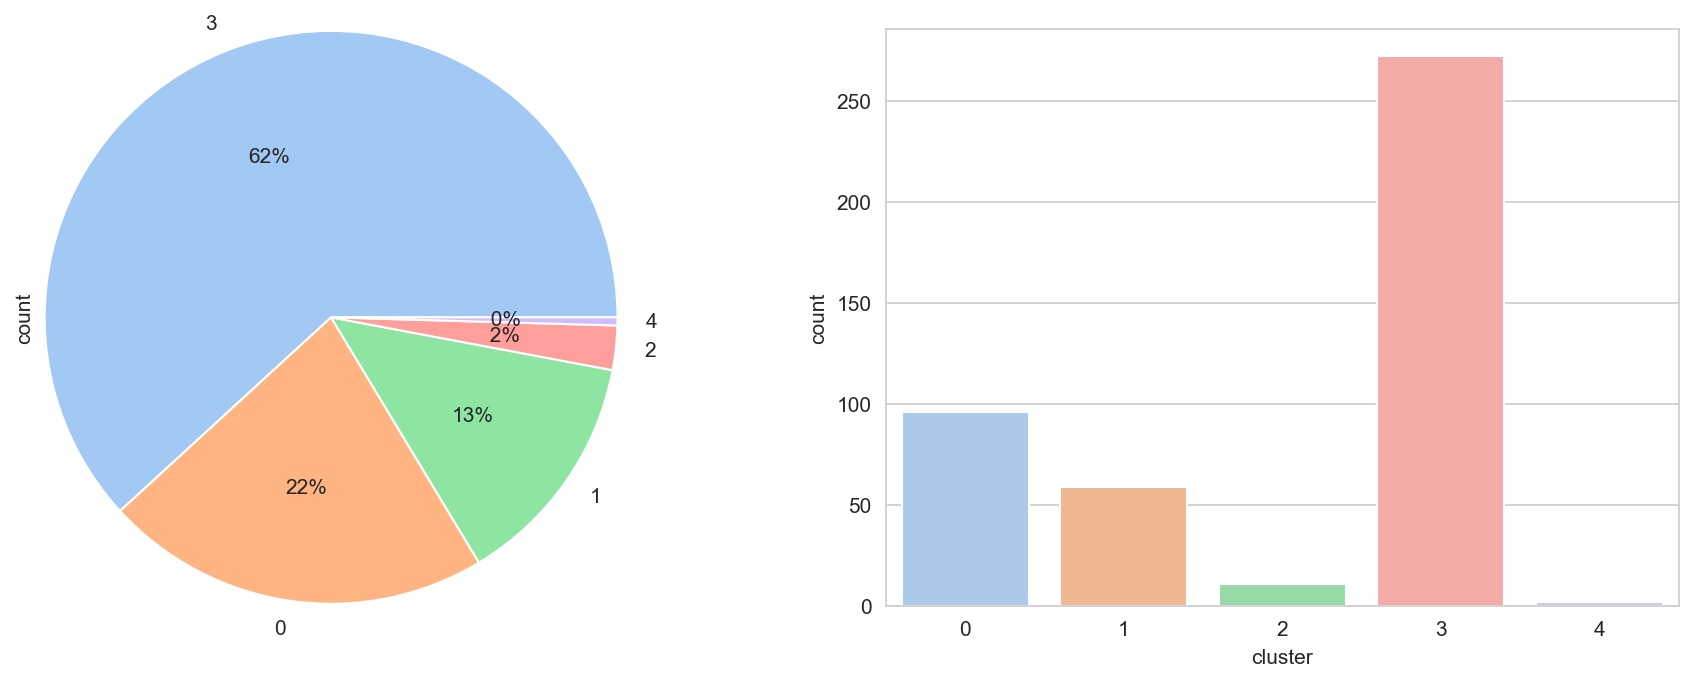

In [11]:
# Cluster Frequency (5 clusters)

scaled_df = scaled_df.drop(['cluster'], axis= 1)
kmeans = KMeans(n_clusters=5, random_state=42)
scaled_df['cluster'] = kmeans.fit_predict(scaled_df)

sns.set_style('whitegrid')
plt.figure(figsize=(15, 5), dpi=150)
plt.subplot(121)
scaled_df['cluster'].value_counts().plot(kind='pie', autopct='%2.f%%', radius=1.24, colors=sns.color_palette('pastel'))
plt.subplot(122)
sns.countplot(data=scaled_df, x='cluster', palette='pastel')
scaled_df['cluster'].value_counts()

We see very few datapoints belonging to cluster 2, which makes it questionable. A deeper dive or an expert opinion could help us determine if they're outliers perhabs.

/var/folders/gh/qryqd19177z9xrl48m08rfg80000gn/T/ipykernel_9656/170373252.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=scaled_df, x='cluster', palette='pastel')


cluster
0    235
3     92
2     78
1     26
5      7
6      1
4      1
Name: count, dtype: int64

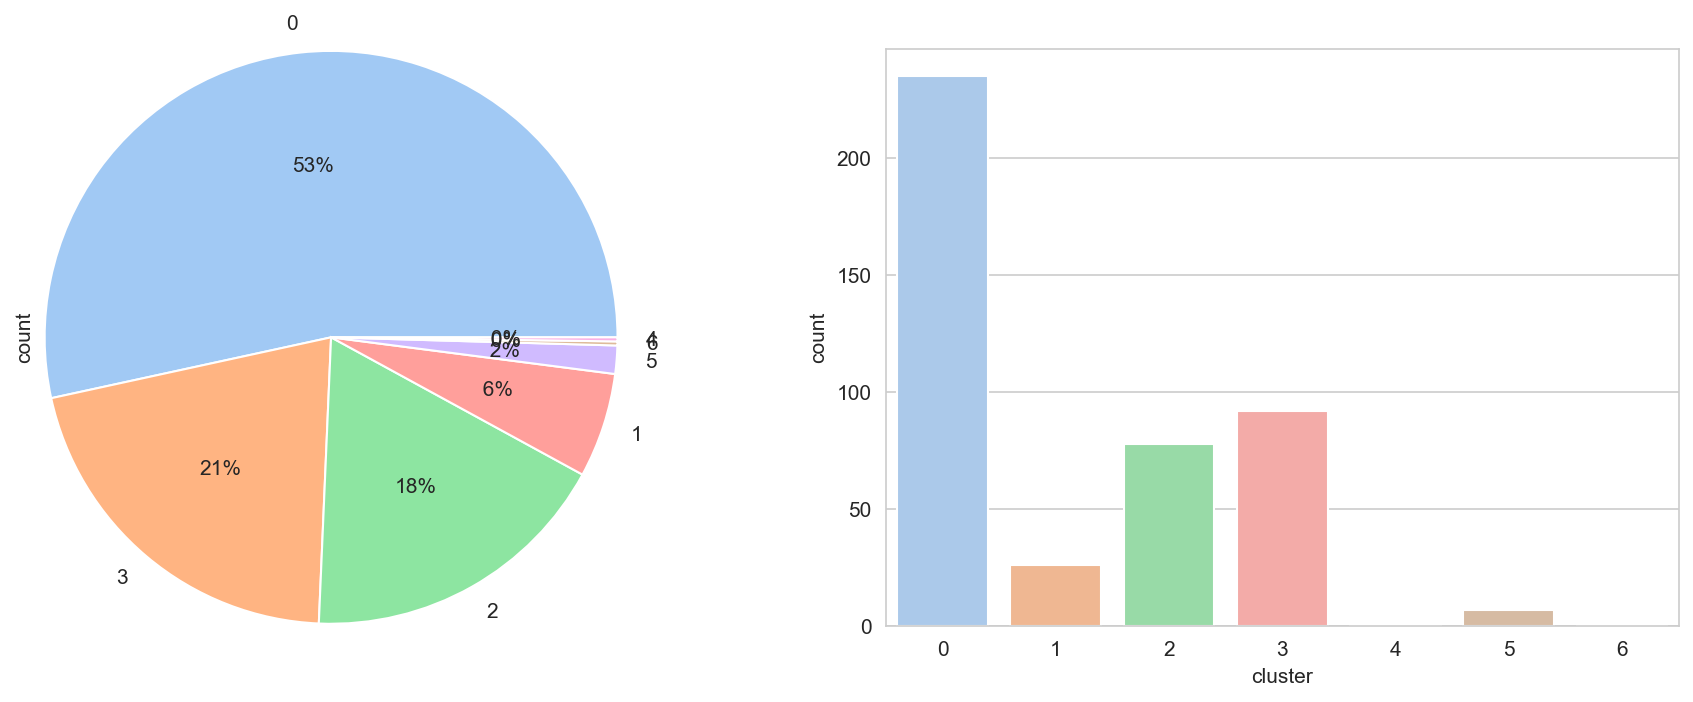

In [12]:
# Cluster Frequency (7 clusters)

scaled_df = scaled_df.drop(['cluster'], axis= 1)
kmeans = KMeans(n_clusters=7, random_state=42)
scaled_df['cluster'] = kmeans.fit_predict(scaled_df)

sns.set_style('whitegrid')
plt.figure(figsize=(15, 5), dpi=150)
plt.subplot(121)
scaled_df['cluster'].value_counts().plot(kind='pie', autopct='%2.f%%', radius=1.24, colors=sns.color_palette('pastel'))
plt.subplot(122)
sns.countplot(data=scaled_df, x='cluster', palette='pastel')
scaled_df['cluster'].value_counts()

- We see very few datapoints belonging to cluster 5, 6 and 4 which makes them questionable. A deeper dive or an expert opinion could help us determine if they're outliers, perhaps.

Because of those questionable clusters in the 7 Clusters Model, we will consider the 5 Clusters Model to be better and will be the one selected to proceed further with our analysis.

<Figure size 800x600 with 0 Axes>

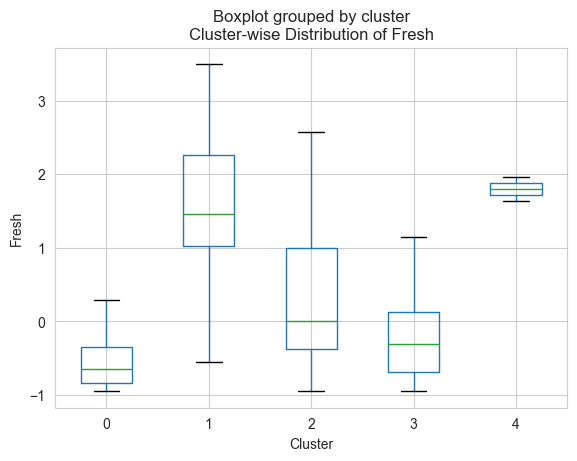

<Figure size 800x600 with 0 Axes>

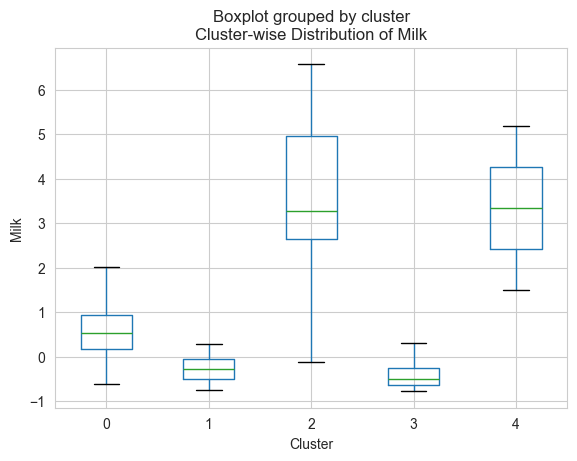

<Figure size 800x600 with 0 Axes>

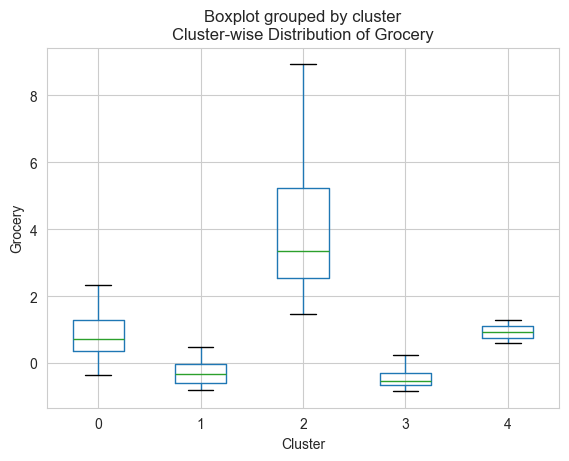

<Figure size 800x600 with 0 Axes>

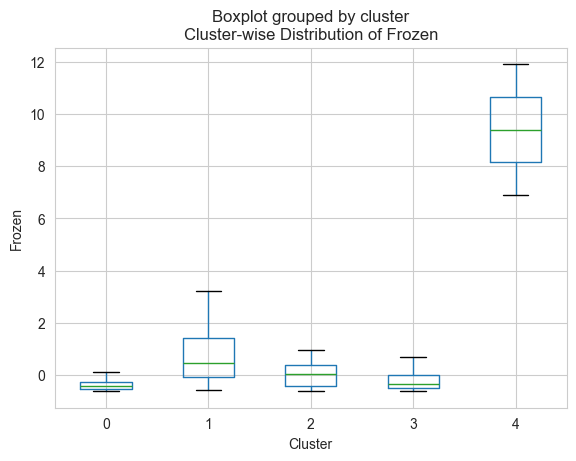

<Figure size 800x600 with 0 Axes>

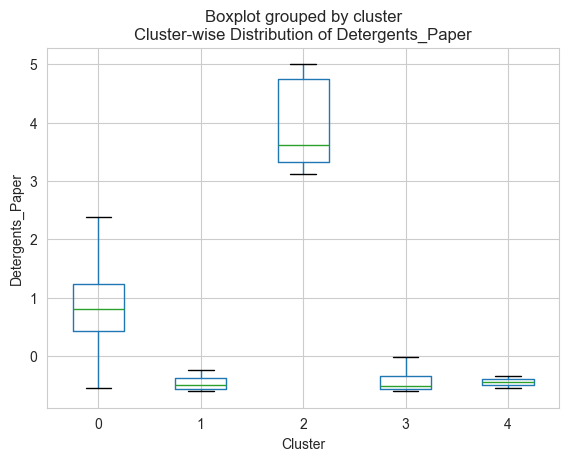

<Figure size 800x600 with 0 Axes>

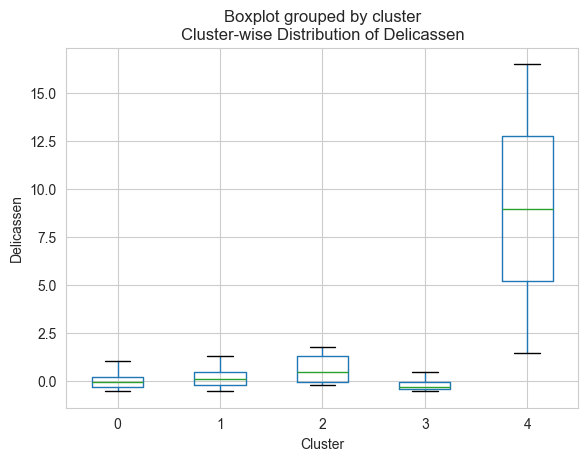

<Figure size 800x600 with 0 Axes>

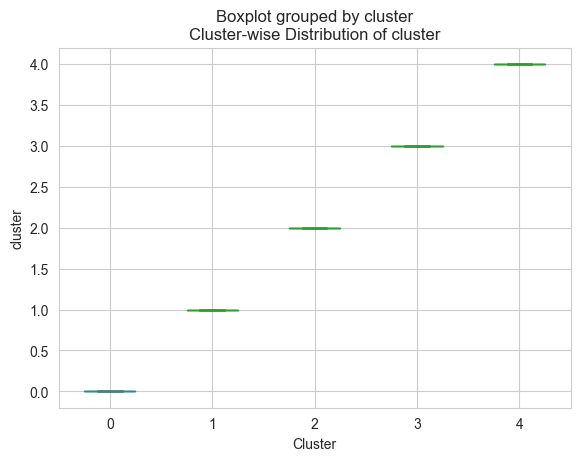

In [13]:
scaled_df = scaled_df.drop(['cluster'], axis= 1)
kmeans = KMeans(n_clusters=5, random_state=42)
scaled_df['cluster'] = kmeans.fit_predict(scaled_df)

for column in scaled_df.columns:
    plt.figure(figsize=(8, 6))
    scaled_df.boxplot(column=[column], by='cluster', showfliers=False)
    plt.title(f'Cluster-wise Distribution of {column}')
    plt.xlabel('Cluster')
    plt.ylabel(column)
    plt.show()

- Cluster 0: Cluster 0 groups low to mid values for all categories and represents 22% of the datapoints.
- Cluster 1: Cluster 1 groups high value datapoints for 'Fresh' categorie and represents 22% of the datapoints 13%.
- Cluster 2: Cluster 2 groups high value for 'Fresh', 'Milk', 'Grocerie' and 'Detergeant_Paper'. This could be justified by the fact that this cluster only includes 2% of the datapoints and the dataset contains very few high values.
- Cluster 3: Cluster 3 groups low values for all categories. This is not surprising since this cluster account for 62% of the datapoints and this dataset is heavily concentrated in low values.
- Cluster 4: Cluster 4 groups the highest values for 'Frozen' and 'Delicassen'. High values for those categories are rare, which support why the cluster groups only 2 datapoints.

# Step 5 (Box-Cox Transformation)

In [14]:
df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [15]:
import numpy as np
from sklearn.preprocessing import PowerTransformer

# Drop non-numeric columns
data_numeric = df.select_dtypes(include=[float, int])

# 1. Log Transformation (add 1 to avoid log(0))
data_log = np.log1p(data_numeric)

# 2. Box-Cox Transformation
# Add a small constant to make all values positive (e.g., 1)
data_numeric_positive = data_numeric + 1

# Apply Box-Cox Transformation
boxcox_transformer = PowerTransformer(method='box-cox')
boxcox_df = boxcox_transformer.fit_transform(data_numeric_positive)  # Result is a NumPy array

# Optional: Convert data_boxcox back to DataFrame for readability
boxcox_df = pd.DataFrame(boxcox_df, columns=data_numeric.columns)


In [16]:
boxcox_df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.413012,0.979454,0.394901,-1.457973,0.620530,0.338074
1,-0.110911,0.995243,0.628376,0.080081,0.751556,0.602222
2,-0.195814,0.888063,0.410688,0.332499,0.793104,2.240051
3,0.458126,-0.965336,-0.154740,1.173953,-0.372736,0.608674
4,1.028870,0.412660,0.346961,0.742061,0.367767,1.737333


In [17]:
# Apply K-means with 5 clusters

kmeans = KMeans(n_clusters=5, random_state=42)
boxcox_df['cluster'] = kmeans.fit_predict(boxcox_df)

<Figure size 800x600 with 0 Axes>

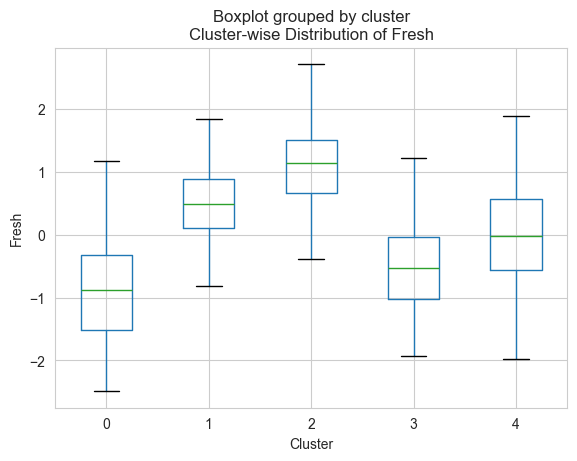

<Figure size 800x600 with 0 Axes>

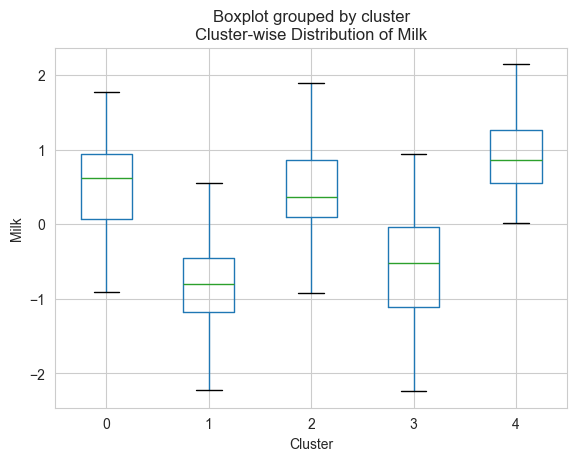

<Figure size 800x600 with 0 Axes>

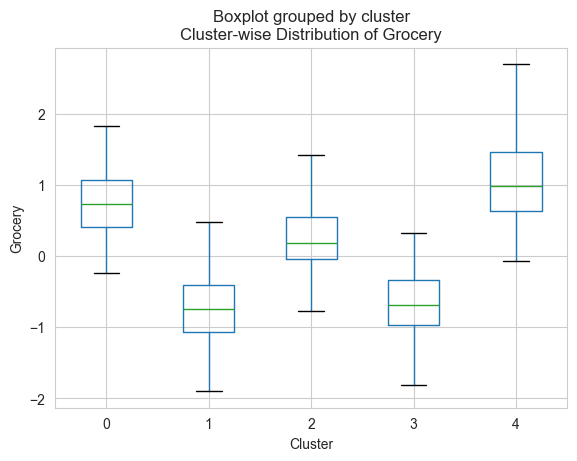

<Figure size 800x600 with 0 Axes>

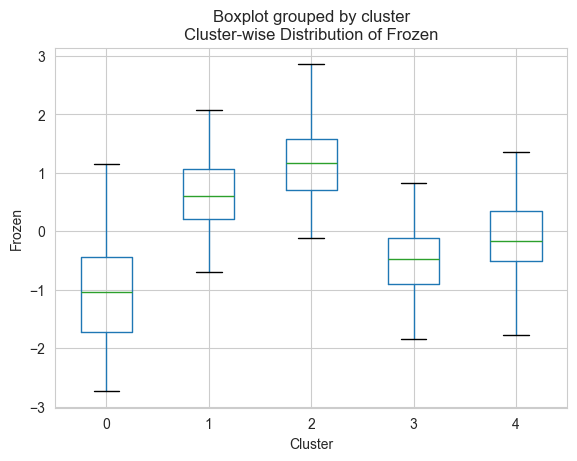

<Figure size 800x600 with 0 Axes>

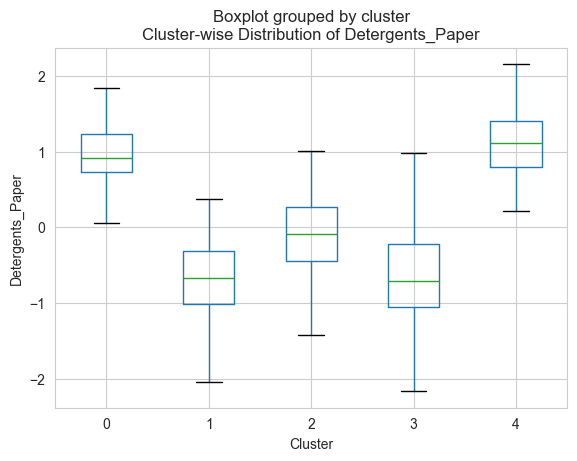

<Figure size 800x600 with 0 Axes>

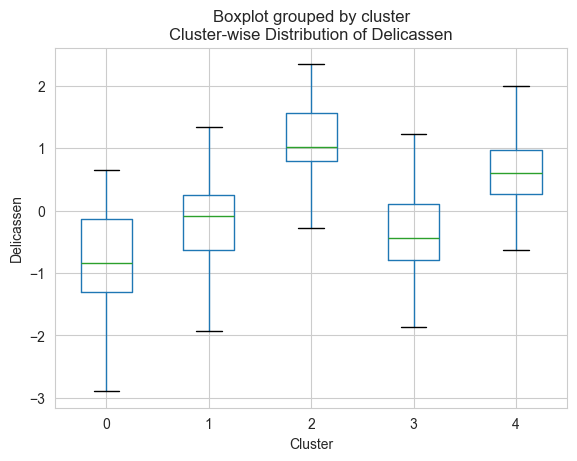

In [18]:
for column in df.columns:
    plt.figure(figsize=(8, 6))
    boxcox_df.boxplot(column=[column], by='cluster', showfliers=False)
    plt.title(f'Cluster-wise Distribution of {column}')
    plt.xlabel('Cluster')
    plt.ylabel(column)
    plt.show()

Clusters have a bigger spread and tend to be concentrated in the mid-range (around 0) when using Box-Cox Transformation, which expected because Box-Cox Transformation normalizes data distribution.

In [19]:
# Clustring Quality Evaluation

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# BOXCOX
print('    BOXCOX')

# Silhouette Score
silhouette_avg = silhouette_score(boxcox_df, boxcox_df['cluster'])
print(f"Silhouette Score: {silhouette_avg:.2f}")

# Final Inertia
print(f"Final Inertia: {kmeans.inertia_:.2f}")

# Calinski-Harabasz Index
ch_score = calinski_harabasz_score(boxcox_df, boxcox_df['cluster'])
print(f"Calinski-Harabasz Score: {ch_score:.2f}")

# Davies-Bouldin Index
db_score = davies_bouldin_score(boxcox_df, boxcox_df['cluster'])
print(f"Davies-Bouldin Score: {db_score:.2f}")

# SCALED 
print('    SCALED')

# Silhouette Score
silhouette_avg = silhouette_score(scaled_data, scaled_df['cluster'])
print(f"Silhouette Score: {silhouette_avg:.2f}")

# Final Inertia
print(f"Final Inertia: {kmeans.inertia_:.2f}")

# Calinski-Harabasz Index
ch_score = calinski_harabasz_score(scaled_data, scaled_df['cluster'])
print(f"Calinski-Harabasz Score: {ch_score:.2f}")

# Davies-Bouldin Index
db_score = davies_bouldin_score(scaled_data, scaled_df['cluster'])
print(f"Davies-Bouldin Score: {db_score:.2f}")

    BOXCOX
Silhouette Score: 0.35
Final Inertia: 1250.40
Calinski-Harabasz Score: 196.38
Davies-Bouldin Score: 1.10
    SCALED
Silhouette Score: 0.37
Final Inertia: 1250.40
Calinski-Harabasz Score: 159.50
Davies-Bouldin Score: 1.03


- Scaled data scores are better apart from the Calinski-Harabasz Score which indicates more compact clusters.

# Step 6 (Clustering Algorithms Comparaison)

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd


# Standardize the data
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_numeric)

# Define clustering algorithms to test
clustering_algorithms = {
    "KMeans": KMeans(n_clusters=5, random_state=42),
    "AgglomerativeClustering": AgglomerativeClustering(n_clusters=5),
    "DBSCAN": DBSCAN()
}

# Function to evaluate clustering algorithms
def evaluate_clustering(data, models):
    results = []
    
    for name, model in models.items():
        # Fit the model and obtain cluster labels using fit_predict()
        cluster_labels = model.fit_predict(data)
        
        # Calculate metrics
        silhouette_avg = silhouette_score(data, cluster_labels)
        ch_score = calinski_harabasz_score(data, cluster_labels)
        db_score = davies_bouldin_score(data, cluster_labels)
        
        # Append results
        results.append({
            "Algorithm": name,
            "Silhouette Score": silhouette_avg,
            "Calinski-Harabasz Score": ch_score,
            "Davies-Bouldin Score": db_score
        })
        
    # Convert results to DataFrame for better readability
    return pd.DataFrame(results)

# Run the evaluation
evaluation_results = evaluate_clustering(data_scaled, clustering_algorithms)

# Display the results
print(evaluation_results)

                 Algorithm  Silhouette Score  Calinski-Harabasz Score  \
0                   KMeans          0.368901               159.503777   
1  AgglomerativeClustering          0.239884               128.645017   
2                   DBSCAN          0.195811                39.064339   

   Davies-Bouldin Score  
0              1.029379  
1              0.972721  
2              1.579362  


- KMeans algorithm has the best score for Silhouette Score and Calinski-Harabaz Score which indicate better defined clusters.
- DBSCAN algorithm has the best score for Davies-Bouldin Score which indicates more compact clusters.
  
- DBSCAN doesn't require any input argument for the number of clusters, while the 2 other do.

# Step 7 (Classification Model)

In [23]:
scaled_df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,cluster
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339,3
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151,0
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293,0
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411,3
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347,1


In [22]:
from sklearn.cluster import KMeans

df['cluster'] = kmeans.fit(scaled_data)
print(kmeans.predict([[0.052933,	0.523568,	-0.041115,	-0.589367,	-0.043569,	-0.066339	]]))
print(kmeans.predict([[-0.391302,	0.544458,	0.170318,	-0.270136,	0.086407,	0.089151]]))
print(kmeans.predict([[0.840239,	-0.052396,	-0.079356,	0.173859,	-0.231918,	1.299347]]))

[3]
[0]
[1]


- An interesting way to dive deeper into the analysis is to try to decompose the data into PC and see if we could get a better clusters and more way of analyzing the data.